In [33]:
from huggingface_hub import snapshot_download

path = snapshot_download(repo_id="mistralai/Timestral-209M", local_dir="./timestral-209m")
print(path)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

/content/timestral-209m


In [34]:
pip install git+https://github.com/mistralai/timestral.git

  Cloning https://github.com/mistralai/timestral.git to /tmp/pip-req-build-3yx3e2zw
  Running command git clone --filter=blob:none --quiet https://github.com/mistralai/timestral.git /tmp/pip-req-build-3yx3e2zw
  Resolved https://github.com/mistralai/timestral.git to commit a534bdbd244d64f3d9d743f46c7bf6fc330ed4ff
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [35]:
import numpy as np
import torch
from timestral import TimestralForecaster

model = TimestralForecaster.from_pretrained(
    "mistralai/Timestral-209M",
    device="cuda" if torch.cuda.is_available() else "cpu"
)

# Synthetic example: one series with 1,000 historical observations.
context = np.random.default_rng(42).standard_normal(1000).cumsum()
forecast = model.forecast(context, prediction_length=96)

median = forecast.median
lower, upper = forecast.quantile(0.1), forecast.quantile(0.9)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

In [36]:

mid = forecast.quantile(0.7)


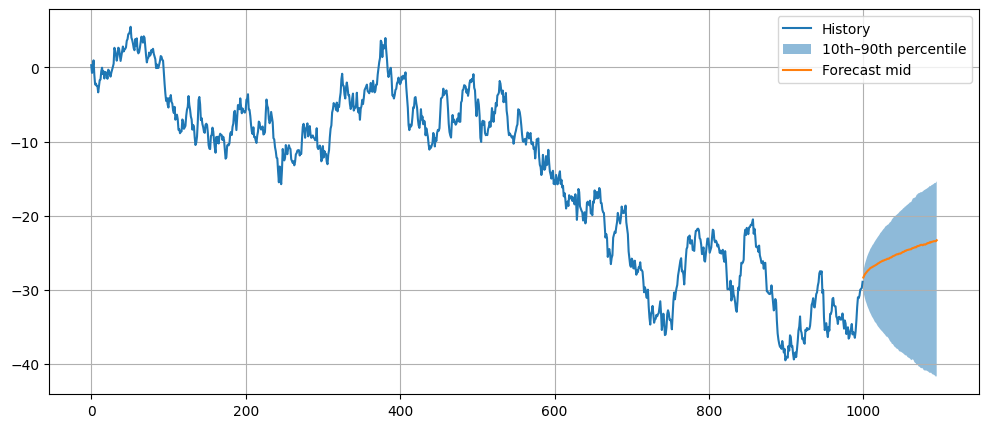

In [37]:
import matplotlib.pyplot as plt

history_x = np.arange(len(context))
forecast_x = np.arange(len(context), len(context) + 96)

median_values = median.detach().cpu().numpy().squeeze()
lower_values = lower.detach().cpu().numpy().squeeze()
upper_values = upper.detach().cpu().numpy().squeeze()
mid_values = mid.detach().cpu().numpy().squeeze()

plt.figure(figsize=(12, 5))
plt.plot(history_x, context, label="History")
plt.fill_between(forecast_x, lower_values, upper_values, alpha=0.5, label="10th–90th percentile")
plt.plot(forecast_x, mid_values, label="Forecast mid")
plt.legend()
plt.grid(True)
plt.show()

In [38]:
# GARCH(1,1): same simulation, reusable for independent seeded paths.
w, a, b = 2e-6, 0.08, 0.90
def simulate_garch(seed=0, T=6000):
    rng = np.random.default_rng(seed)
    sig2 = np.empty(T); r = np.empty(T)
    sig2[0] = w / (1 - a - b)
    for t in range(T):
        r[t] = np.sqrt(sig2[t]) * rng.standard_t(6) * np.sqrt(4/6)  # unit-variance t
        if t + 1 < T:
            sig2[t+1] = w + a * r[t]**2 + b * sig2[t]
    garch_logvar = np.log(sig2)
    return sig2, r, garch_logvar

T = 6000
sig2, r, garch_logvar = simulate_garch(0, T)


### Monte Carlo oracle for log variance
Compare Timestral's median and 10–90% interval with the same quantiles of simulated future **log variance**. The dashed reference is `log(E[σ² | state])`, not a median. Jensen's inequality orders `E[log σ²]` and `log(E[σ²])`; it does not in general order the median. Likewise, `log(sbar)` is not the stationary median of log variance.

This is a **full-state oracle**: it knows `sig2[t0 + 1]` (equivalently the current variance and realized return), while Timestral sees log variance only through `t0`. Its first-step interval is therefore degenerate. Matching quantile statistics removes the earlier mean/median mismatch, but does not equalize information sets. Monte Carlo quantiles have sampling error.

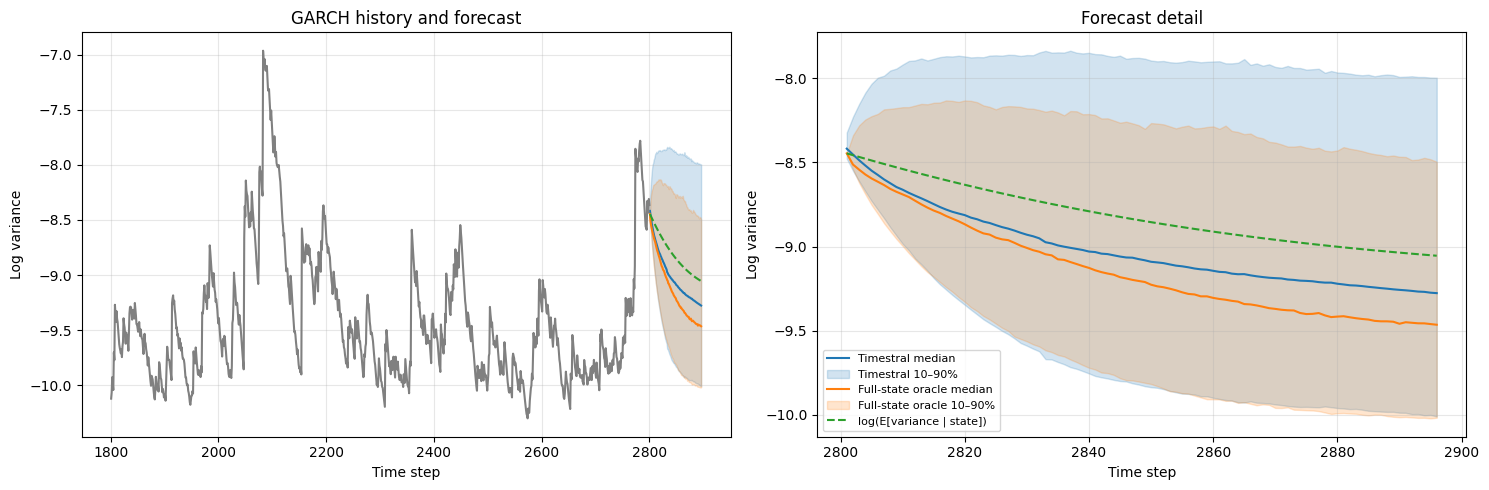

In [39]:
sbar = w / (1 - a - b)

def garch_opt(sig2_next, k):
    # k=1 is the known next variance, before any future return is sampled.
    k = np.asarray(k)
    mean_path = sbar + (a + b) ** (k - 1) * (sig2_next - sbar)
    # The first variance is known exactly; avoid subtract/add roundoff.
    return np.where(k == 1, sig2_next, mean_path)


def simulate_future(sig2_next, H, n=5000, seed=12345):
    """Full-state conditional log-variance paths, shape (H, n)."""
    if sig2_next <= 0 or H < 1 or n < 1:
        raise ValueError("Need positive variance, horizon, and path count")
    future_rng = np.random.default_rng(seed)  # independent of the history RNG
    s2 = np.full(n, sig2_next, dtype=float)
    out = np.empty((H, n))
    for k in range(H):
        out[k] = s2
        if k + 1 < H:
            future_r = np.sqrt(s2) * future_rng.standard_t(6, n) * np.sqrt(4 / 6)
            s2 = w + a * future_r**2 + b * s2
    return np.log(out)


def forecast_quantiles(context, H):
    prediction = model.forecast(context, prediction_length=H)
    values = np.stack([
        prediction.quantile(q).detach().cpu().numpy().reshape(-1)
        for q in (0.1, 0.5, 0.9)
    ])
    if values.shape != (3, H):
        raise ValueError(f"Unexpected forecast shape: {values.shape}")
    return values


t0, H, context_length = 2800, 96, 1000
context = garch_logvar[t0 + 1 - context_length:t0 + 1]
paths = simulate_future(sig2[t0 + 1], H)
true_lo, true_med, true_hi = np.quantile(paths, [0.1, 0.5, 0.9], axis=1)
lower_values, median_values, upper_values = forecast_quantiles(context, H)
opt = garch_opt(sig2[t0 + 1], np.arange(1, H + 1))

history_x = np.arange(t0 + 1 - context_length, t0 + 1)
forecast_x = np.arange(t0 + 1, t0 + H + 1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax in axes:
    ax.plot(forecast_x, median_values, color="C0", label="Timestral median")
    ax.fill_between(forecast_x, lower_values, upper_values, color="C0", alpha=0.2,
                    label="Timestral 10–90%")
    ax.plot(forecast_x, true_med, color="C1", label="Full-state oracle median")
    ax.fill_between(forecast_x, true_lo, true_hi, color="C1", alpha=0.2,
                    label="Full-state oracle 10–90%")
    ax.plot(forecast_x, np.log(opt), color="C2", linestyle="--",
            label="log(E[variance | state])")
    ax.set(xlabel="Time step", ylabel="Log variance")
    ax.grid(alpha=0.3)
axes[0].plot(history_x, context, color="0.5", label="History")
axes[0].set_title("GARCH history and forecast")
axes[1].set_title("Forecast detail")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## Quantitative evaluation — preregistered rules
These rules are specified before computing results, on simulated GARCH(1,1) with ω=2e-6, α=0.08, β=0.90, unit-variance Student-t(6) innovations and initial variance ω/(1−α−β).

- **Learns the process:** oracle QLIKE loss ratio ≤1.05 at every horizon 1…22.
- **Calibrated:** empirical 10–90% coverage is within 80% ±3 percentage points at every horizon.
- **Robust:** the same QLIKE configuration ordering across seeds, context lengths and model sizes. Operationally, every seed must preserve the pooled ordering within each model's context ablation and each context's model ablation (ties use tolerance 1e-10).
- **Beats fitted GARCH:** lower average QLIKE and two-sided DM p<0.05, with negative Timestral-minus-GARCH loss difference.

**Predeclared limitation:** at k=1 the full-state oracle predicts the realized variance exactly, giving zero QLIKE and MSE. The ratio and its CI are undefined; no epsilon is added. Thus the literal “learns the process” rule is unassessable. A separately labeled k=2…22 diagnostic is provided, without substituting it for that rule.

Timestral sees latent log variance through t0; the oracle also knows the return at t0, and fitted GARCH sees returns through t0. These information sets differ. The quantile-integrated mean uses flat 1% tails and is approximate. Results concern only this simulated process and these settings, not financial returns generally.

Sources: [Timestral model IDs, quantiles and context limit](https://github.com/mistralai/timestral/); [arch analytical forecasts and origin alignment](https://arch.readthedocs.io/en/latest/univariate/forecasting.html).

In [40]:
# Run once in this notebook's kernel if needed:
# %pip install arch pandas scipy
import gc
import hashlib
import json
import os
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError
import pandas as pd
from scipy.stats import norm
from IPython.display import display, Markdown

H = 96
PATH_SEEDS = tuple(range(1000, 1050))
CONTEXTS = (256, 512, 1024, 2048, "full")
MODEL_IDS = {size: f"mistralai/Timestral-{size}M" for size in (5, 28, 123, 209)}
N_ORIGINS = 128  # > NW_LAG; same origins for every configuration
EVAL_T = 2048 + N_ORIGINS * H
ORIGINS = np.arange(2047, EVAL_T - H, H)
N_MC, N_BOOT, NW_LAG = 5000, 1000, H - 1
BOOT_BLOCK = 12  # circular blocks of neighboring forecast origins
CACHE = Path("evaluation/cache")
CACHE.mkdir(parents=True, exist_ok=True)
CACHE_SCHEMA = "garch-eval-v1"
assert len(ORIGINS) == N_ORIGINS and ORIGINS[-1] + H < EVAL_T
assert np.all(np.diff(ORIGINS) >= H) and N_ORIGINS > NW_LAG
assert EVAL_T <= 32768, "Full history must fit Timestral's context limit"

def package_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return "uninstalled"

def cached(namespace, metadata, compute):
    key = json.dumps(metadata, sort_keys=True, separators=(",", ":"))
    digest = hashlib.sha256(key.encode()).hexdigest()
    directory = CACHE / namespace
    directory.mkdir(exist_ok=True)
    target = directory / f"{digest}.npz"
    if target.exists():
        with np.load(target, allow_pickle=False) as saved:
            assert str(saved["metadata"]) == key
            return {k: saved[k].copy() for k in saved.files if k != "metadata"}
    result = compute()
    temp = target.with_suffix(f".{os.getpid()}.tmp")
    with temp.open("wb") as stream:
        np.savez_compressed(stream, metadata=key, **result)
    temp.replace(target)
    return result

# evaluate's path state is explicit here and set once per seeded path by the runner.
ACTIVE_PATH = None
ACTIVE_MODEL_ID = None
ACTIVE_REVISION = None

def as_numpy(value):
    return value.detach().cpu().numpy().reshape(-1)

def evaluate(t0, context_len, model):
    seed, variance, returns, logvar = ACTIVE_PATH
    length = t0 + 1 if context_len == "full" else int(context_len)
    assert length <= t0 + 1 and t0 + H < len(variance)
    history = logvar[t0 + 1 - length:t0 + 1].copy()
    assert len(history) == length and history[-1] == logvar[t0]
    base = dict(schema=CACHE_SCHEMA, seed=int(seed), t0=int(t0), H=H,
                T=len(variance), w=w, a=a, b=b, df=6,
                path_hash=hashlib.sha256(variance.tobytes() + returns.tobytes()).hexdigest())
    model_key = dict(base, context_len=context_len, model=ACTIVE_MODEL_ID,
                     revision=ACTIVE_REVISION, timestral=package_version("timestral"),
                     torch=package_version("torch"), numpy=package_version("numpy"))
    def forecast_once():
        with torch.inference_mode():
            fc = model.forecast(history, prediction_length=H)
        levels = np.asarray(fc.quantile_levels, dtype=float)
        quantiles = np.stack([as_numpy(fc.quantile(float(q))) for q in levels])
        assert len(levels) == 21 and np.all(np.diff(levels) > 0)
        assert np.isclose(levels[0], .01) and np.isclose(levels[-1], .99)
        assert quantiles.shape == (21, H) and np.isfinite(quantiles).all()
        assert np.all(np.diff(quantiles, axis=0) >= -1e-6), "Crossing quantiles"
        v = np.exp(quantiles.astype(float))
        trapezoid = getattr(np, "trapezoid", None)
        if trapezoid is None:  # NumPy < 2.0
            trapezoid = np.trapz
        mean_var = trapezoid(v, levels, axis=0) + .01*v[0] + .01*v[-1]
        assert np.all(np.isfinite(mean_var) & (mean_var > 0))
        return dict(levels=levels, quantiles=quantiles,
                    median=as_numpy(fc.median), mean_var=mean_var)
    ts = cached("timestral", model_key, forecast_once)
    def oracle_once():
        # Reuse the existing oracle simulation and closed-form mean.
        mc_seed = np.random.SeedSequence([int(seed), int(t0), 9281])
        continuations = simulate_future(variance[t0 + 1], H, N_MC, seed=mc_seed)
        return dict(opt=garch_opt(variance[t0 + 1], np.arange(1, H + 1)),
                    oracle_quantiles=np.quantile(continuations, [.1, .5, .9], axis=1),
                    realized=variance[t0 + 1:t0 + 1 + H])
    oracle = cached("oracle", dict(base, n_mc=N_MC), oracle_once)
    def fit_once():
        from arch import arch_model
        # Scale returns to percent for numerical conditioning; undo variance scale.
        fit = arch_model(100 * returns[:t0 + 1], mean="Zero", vol="GARCH",
                         p=1, o=0, q=1, dist="t", rescale=False).fit(disp="off")
        if fit.convergence_flag != 0:
            raise RuntimeError(f"GARCH failed to converge: seed={seed}, t0={t0}")
        fitted = fit.forecast(horizon=H, method="analytic", reindex=False).variance.iloc[-1].to_numpy()/10000
        assert np.all(np.isfinite(fitted) & (fitted > 0))
        return dict(fitted=fitted)
    baseline = cached("arch", dict(base, arch=package_version("arch")), fit_once)
    np.testing.assert_array_equal(oracle["realized"], variance[t0 + 1:t0 + 1 + H])
    # Accept roundoff in older cached oracle paths, but reject misalignment.
    np.testing.assert_allclose(oracle["opt"][0], variance[t0 + 1],
                               rtol=1e-14, atol=0,
                               err_msg="Oracle first step is not variance[t0 + 1]")
    # Normalize only after checking, keeping k=1 oracle loss exactly zero.
    oracle["opt"][0] = variance[t0 + 1]
    return dict(**ts, **oracle, **baseline)

### Inference and checks
QLIKE is primary, variance MSE secondary. Ratios are ratios of aggregate losses, not averages of individual ratios. CIs use paired hierarchical bootstrap: resample independent paths, then circular blocks of 12 neighboring start points within each sampled path. The same resamples are used for numerator and denominator. These are pointwise 95% intervals.

DM uses Timestral-minus-baseline QLIKE differences across origins, with Bartlett Newey–West lag 95 **in origin units**, computed separately within each path and pooled without crossing path boundaries. This is conservative relative to the nonoverlapping 96-step windows; each path has 128 origins. Normal asymptotic p-values are descriptive with this bandwidth/sample size. No claim of independence between starts is made. Oracle superiority checks use one-sided DM tests with Bonferroni correction over all configurations and horizons plus the horizon average; failure stops reporting for an indexing/lookahead audit. Finite-sample apparent superiority can also be a statistical false alarm; a failing run must not be reported as evidence of beating the oracle.

In [41]:
def qlike(realized, forecast):
    assert np.all(realized > 0) and np.all(forecast > 0)
    x = realized / forecast - 1
    return x - np.log1p(x)

def loss_ratio(numerator, denominator):
    numerator, denominator = np.broadcast_arrays(numerator, denominator)
    result = np.full(numerator.shape, np.nan)
    return np.divide(numerator, denominator, out=result, where=denominator > 0)

def dm_test(difference, lag=NW_LAG):
    # difference: independent path × chronologically ordered origin [× horizon]
    d = np.asarray(difference, dtype=float)
    if d.ndim == 2:
        d = d[..., None]
    P, O, _ = d.shape
    assert O > lag >= H - 1 and P > 1
    centered = d - d.mean(axis=1, keepdims=True)
    lrv = np.mean(centered**2, axis=1)
    for j in range(1, lag + 1):
        gamma = (centered[:, j:] * centered[:, :-j]).sum(axis=1) / O
        lrv += 2 * (1 - j/(lag + 1)) * gamma
    se = np.sqrt(np.maximum(lrv.sum(axis=0), 0) / (P**2 * O))
    mean = d.mean(axis=(0, 1))
    z = np.divide(mean, se, out=np.zeros_like(mean), where=se > 0)
    z = np.where((se == 0) & (mean != 0), np.copysign(np.inf, mean), z)
    return dict(mean=mean, p=2*norm.sf(np.abs(z)), p_less=norm.cdf(z))

def bootstrap_ratio(ts_loss, oracle_loss):
    # Compute all horizons plus their average with common paired resamples.
    P, O, K = ts_loss.shape
    left = np.concatenate([ts_loss, ts_loss.mean(axis=2, keepdims=True)], axis=2)
    right = np.concatenate([oracle_loss, oracle_loss.mean(axis=2, keepdims=True)], axis=2)
    boot_rng = np.random.default_rng(6173)
    samples = np.empty((N_BOOT, K + 1))
    for bidx in range(N_BOOT):
        paths = boot_rng.integers(P, size=P)
        starts = boot_rng.integers(O, size=(P, int(np.ceil(O/BOOT_BLOCK))))
        origins = ((starts[..., None] + np.arange(BOOT_BLOCK)) % O).reshape(P, -1)[:, :O]
        samples[bidx] = loss_ratio(left[paths[:, None], origins].mean(axis=(0, 1)),
                                  right[paths[:, None], origins].mean(axis=(0, 1)))
    valid = np.isfinite(samples).all(axis=0)
    ci = np.full((2, K + 1), np.nan)
    ci[:, valid] = np.quantile(samples[:, valid], [.025, .975], axis=0)
    return ci

def summarize(records):
    def stack(key):
        return np.asarray([[record[key] for record in path] for path in records])
    y, f, opt, fitted = (stack(key) for key in ("realized", "mean_var", "opt", "fitted"))
    levels = records[0][0]["levels"]
    assert all(np.array_equal(record["levels"], levels) for path in records for record in path)
    quantiles = stack("quantiles")
    def q(level):
        index = np.flatnonzero(np.isclose(levels, level))
        assert len(index) == 1
        return quantiles[:, :, index[0]]
    log_y = np.log(y)
    losses = qlike(y, f)
    oracle_loss = qlike(y, opt)
    fitted_loss = qlike(y, fitted)
    mse, oracle_mse = (y-f)**2, (y-opt)**2
    dm_o, dm_g = dm_test(losses-oracle_loss), dm_test(losses-fitted_loss)
    avg_o = dm_test((losses-oracle_loss).mean(axis=2))
    avg_g = dm_test((losses-fitted_loss).mean(axis=2))
    threshold = .05 / (len(MODEL_IDS)*len(CONTEXTS)*(H+1))
    assert not np.any((dm_o["mean"] < 0) & (dm_o["p_less"] < threshold)), "Oracle audit failed: stop and inspect alignment/lookahead"
    assert not (avg_o["mean"][0] < 0 and avg_o["p_less"][0] < threshold), "Oracle audit failed for average loss"
    ci = bootstrap_ratio(losses, oracle_loss)
    mse_ci = bootstrap_ratio(mse, oracle_mse)
    metrics = dict(qlike_gap=(losses-oracle_loss).mean(axis=(0,1)), qlike=losses.mean(axis=(0,1)), oracle_qlike=oracle_loss.mean(axis=(0,1)),
                   fitted_qlike=fitted_loss.mean(axis=(0,1)),
                   ratio=loss_ratio(losses.mean(axis=(0,1)), oracle_loss.mean(axis=(0,1))),
                   mse=mse.mean(axis=(0,1)), oracle_mse=oracle_mse.mean(axis=(0,1)),
                   mse_ratio=loss_ratio(mse.mean(axis=(0,1)), oracle_mse.mean(axis=(0,1))),
                   coverage80=((log_y >= q(.1)) & (log_y <= q(.9))).mean(axis=(0,1)),
                   coverage90=((log_y >= q(.05)) & (log_y <= q(.95))).mean(axis=(0,1)),
                   below_median=(log_y < stack("median")).mean(axis=(0,1)),
                   bias=(f-y).mean(axis=(0,1)),
                   gap10=np.abs(q(.1)-stack("oracle_quantiles")[:,:,0]).mean(axis=(0,1)),
                   gap50=np.abs(q(.5)-stack("oracle_quantiles")[:,:,1]).mean(axis=(0,1)),
                   gap90=np.abs(q(.9)-stack("oracle_quantiles")[:,:,2]).mean(axis=(0,1)),
                   dm_oracle_p=dm_o["p"], dm_garch_p=dm_g["p"],
                   ratio_lo=ci[0,:H], ratio_hi=ci[1,:H],
                   mse_ratio_lo=mse_ci[0,:H], mse_ratio_hi=mse_ci[1,:H])
    avg = {key: value.mean() for key,value in metrics.items()}
    avg.update(ratio=float(loss_ratio(losses.mean(),oracle_loss.mean())),
               mse_ratio=float(loss_ratio(mse.mean(),oracle_mse.mean())),
               ratio_lo=ci[0,-1], ratio_hi=ci[1,-1],
               mse_ratio_lo=mse_ci[0,-1], mse_ratio_hi=mse_ci[1,-1],
               dm_oracle_p=avg_o["p"][0], dm_garch_p=avg_g["p"][0])
    return dict(curves=metrics, average=avg, seed_loss=losses.mean(axis=(1,2)))

# Unit check: use independent continuations, compare to the existing analytical oracle.
check_s2 = sig2[2801]
check_paths = np.exp(simulate_future(check_s2, H, n=100000, seed=701))
check_opt = garch_opt(check_s2, np.arange(1, H+1))
check_se = check_paths.std(axis=1, ddof=1)/np.sqrt(check_paths.shape[1])
# Bonferroni normal threshold across 96 horizons, 0.1% family significance.
assert np.all(np.abs(check_paths.mean(axis=1)-check_opt) <=
              norm.ppf(1-.001/(2*H))*check_se + 1e-14)
np.testing.assert_allclose(check_paths[0], check_opt[0], rtol=1e-14)
del check_paths
print("Monte Carlo mean and first-unseen-step alignment check passed.")

Monte Carlo mean and first-unseen-step alignment check passed.


In [ ]:
# Full experiment: 50 paths × 128 origins × 5 contexts × 4 models = 128,000 forecasts.
# This cell downloads missing models and can take substantial time. Reruns reuse disk caches.
# Pin each resolved Hugging Face commit in a manifest before loading any weights.
from huggingface_hub import model_info
from arch import arch_model  # fail early if the notebook kernel needs arch installed
manifest_path = CACHE.parent / "model_revisions.json"
if manifest_path.exists():
    REVISIONS = json.loads(manifest_path.read_text())
else:
    REVISIONS = {repo: model_info(repo).sha for repo in MODEL_IDS.values()}
    manifest_path.write_text(json.dumps(REVISIONS, indent=2))
results = {}
for size, repo in MODEL_IDS.items():
    ACTIVE_MODEL_ID, ACTIVE_REVISION = repo, REVISIONS[repo]
    eval_model = TimestralForecaster.from_pretrained(
        repo, revision=ACTIVE_REVISION, device="cuda" if torch.cuda.is_available() else "cpu")
    for context_len in CONTEXTS:
        records = []
        for seed in PATH_SEEDS:
            variance, returns, logvar = simulate_garch(seed, EVAL_T)
            ACTIVE_PATH = (seed, variance, returns, logvar)
            records.append([evaluate(int(origin), context_len, eval_model) for origin in ORIGINS])
            print(f"{size}M / context={context_len} / seed={seed} complete", flush=True)
        results[(size, context_len)] = summarize(records)
        del records
    del eval_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

5M / context=256 / seed=1000 complete
5M / context=256 / seed=1001 complete
5M / context=256 / seed=1002 complete
5M / context=256 / seed=1003 complete
5M / context=256 / seed=1004 complete
5M / context=256 / seed=1005 complete
5M / context=256 / seed=1006 complete
5M / context=256 / seed=1007 complete
5M / context=256 / seed=1008 complete
5M / context=256 / seed=1009 complete
5M / context=256 / seed=1010 complete
5M / context=256 / seed=1011 complete
5M / context=256 / seed=1012 complete
5M / context=256 / seed=1013 complete
5M / context=256 / seed=1014 complete
5M / context=256 / seed=1015 complete
5M / context=256 / seed=1016 complete
5M / context=256 / seed=1017 complete
5M / context=256 / seed=1018 complete
5M / context=256 / seed=1019 complete
5M / context=256 / seed=1020 complete
5M / context=256 / seed=1029 complete
5M / context=256 / seed=1030 complete
5M / context=256 / seed=1031 complete
5M / context=256 / seed=1032 complete
5M / context=256 / seed=1033 complete
5M / context

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

28M / context=256 / seed=1000 complete
28M / context=256 / seed=1001 complete
28M / context=256 / seed=1002 complete
28M / context=256 / seed=1003 complete
28M / context=256 / seed=1004 complete
28M / context=256 / seed=1005 complete
28M / context=256 / seed=1006 complete
28M / context=256 / seed=1007 complete
28M / context=256 / seed=1008 complete
28M / context=256 / seed=1009 complete
28M / context=256 / seed=1010 complete
28M / context=256 / seed=1011 complete
28M / context=256 / seed=1012 complete
28M / context=256 / seed=1013 complete
28M / context=256 / seed=1014 complete
28M / context=256 / seed=1015 complete
28M / context=256 / seed=1016 complete
28M / context=256 / seed=1017 complete
28M / context=256 / seed=1018 complete
28M / context=256 / seed=1019 complete
28M / context=256 / seed=1020 complete
28M / context=256 / seed=1021 complete
28M / context=256 / seed=1022 complete
28M / context=256 / seed=1023 complete
28M / context=256 / seed=1024 complete
28M / context=256 / seed=

In [ ]:
rows, horizon_rows = [], []
for (size, context_len), result in results.items():
    config = dict(model=f"{size}M", context=context_len)
    avg, curves = result["average"], result["curves"]
    rows.append(dict(**config, **avg,
                     ratio_CI=f"{avg['ratio']:.3f} [{avg['ratio_lo']:.3f}, {avg['ratio_hi']:.3f}]"))
    for k in (1, 5, 22, 96):
        horizon_rows.append(dict(**config, horizon=str(k), **{m:v[k-1] for m,v in curves.items()}))
    horizon_rows.append(dict(**config, horizon="1..96", **avg))
summary = pd.DataFrame(rows)
horizon_summary = pd.DataFrame(horizon_rows)
display(summary[["model", "context", "ratio_CI", "coverage80", "coverage90", "below_median",
                 "bias", "dm_oracle_p", "dm_garch_p"]])
display(horizon_summary)
summary.to_csv("evaluation/summary.csv", index=False)
horizon_summary.to_csv("evaluation/horizon_summary.csv", index=False)
all_horizons = pd.DataFrame([
    dict(model=f"{size}M", context=context_len, horizon=k+1, **{m:v[k] for m,v in result["curves"].items()})
    for (size, context_len),result in results.items() for k in range(H)])
all_horizons.to_csv("evaluation/all_horizons.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for (size, context_len), result in results.items():
    c = result["curves"]
    label = f"{size}M / {context_len}"
    for ax, metric in zip(axes, ("ratio", "coverage80", "bias")):
        ax.plot(np.arange(1,H+1), c[metric], label=label, alpha=.8)
for ax,title,target in zip(axes, ("QLIKE ratio (k=1 undefined)", "10–90% coverage", "Variance bias"), (1,.8,0)):
    ax.axhline(target, color="black", linestyle="--")
    ax.set(xlabel="Horizon", title=title)
    ax.grid(alpha=.2)
axes[1].axhspan(.77,.83, color="gray", alpha=.15)
axes[2].legend(bbox_to_anchor=(1.02,1), loc="upper left", fontsize=7)
fig.tight_layout()
fig.savefig("evaluation/horizon_metrics.png", bbox_inches="tight", dpi=150)
plt.show()

fig, axes = plt.subplots(1,2,figsize=(13,4))
for size in MODEL_IDS:
    axes[0].plot(range(len(CONTEXTS)), [results[size,c]["average"]["ratio"] for c in CONTEXTS], marker="o", label=f"{size}M")
for c in CONTEXTS:
    axes[1].plot(list(MODEL_IDS), [results[s,c]["average"]["ratio"] for s in MODEL_IDS], marker="o", label=str(c))
axes[0].set_xticks(range(len(CONTEXTS)), [str(c) for c in CONTEXTS])
axes[0].set_xlabel("Context length (full grows with t0)")
axes[1].set_xlabel("Model size (millions of parameters)")
for ax in axes:
    ax.set_ylabel("Average QLIKE ratio to oracle")
    ax.axhline(1, color="black", linestyle="--")
    ax.legend()
    ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig("evaluation/ablations.png", dpi=150)
plt.show()

# Strict preregistered ordering check, not a post-hoc choice of favorable seeds.
def stable_order(keys):
    pooled = np.array([results[key]["average"]["qlike"] for key in keys])
    seed_values = np.stack([results[key]["seed_loss"] for key in keys])
    for i in range(len(keys)):
        for j in range(i):
            if abs(pooled[i]-pooled[j]) > 1e-10:
                if not np.all((seed_values[i]-seed_values[j])*np.sign(pooled[i]-pooled[j]) >= -1e-10):
                    return False
    return True
robust = all(stable_order([(s,c) for c in CONTEXTS]) for s in MODEL_IDS) and all(
    stable_order([(s,c) for s in MODEL_IDS]) for c in CONTEXTS)
verdicts = []
for key,result in results.items():
    c, avg = result["curves"], result["average"]
    verdicts.append(dict(model=f"{key[0]}M", context=key[1],
        learns_process="Unassessable: k=1 oracle loss is zero",
        k2_to_22_diagnostic=bool(np.all(c["ratio"][1:22] <= 1.05)),
        calibrated=bool(np.all(np.abs(c["coverage80"]-.8) <= .03)),
        robust_ordering=robust,
        beats_fitted_garch=bool(avg["qlike"] < avg["fitted_qlike"] and avg["dm_garch_p"] < .05)))
verdict_table = pd.DataFrame(verdicts)
display(verdict_table)
verdict_table.to_csv("evaluation/verdicts.csv", index=False)
display(Markdown(
    f"Evaluated **simulated** GARCH(1,1), ω={w}, α={a}, β={b}, standardized t(6), "
    f"{len(PATH_SEEDS)} seeded paths and {len(ORIGINS)} nonoverlapping origins per path; H={H}. "
    "The tables apply the preregistered rules only to these settings. DM p-values for fitted-GARCH "
    "comparisons are unadjusted exploratory comparisons across configurations. "
    "Full-state oracle k=1 ratios are undefined. No real-data or other-process generalization is implied."))

## S&P 500: rolling 30-trading-day GARCH, HAR and Timestral variance forecasts
Download the S&P 500 price index (`^GSPC`) with **yfinance**. Display November 2021–November 2026 (available completed daily bars), with two preceding years for estimation. Change the dates or use `SPY` for an investable ETF proxy.

Fit a zero-mean Student-t GARCH(1,1) to daily **log returns**, not to the variance series. Refit each trading day on the latest 504 returns. At each origin, forecast the next 30 trading days and average their conditional variances. Compare this to the average squared return over those exact future dates: a noisy realized-variance proxy under the zero-mean assumption. Also show the conventional trailing 30-day sample variance. All variance curves use decimal-return variance ×252 (annualized).

The forecast comparison is dated at the **end of its target window**, so the forecast shown at a date was issued 30 trading observations earlier. Only complete realized windows are evaluated. Adjacent windows overlap. The separate latest forecast chart shows horizons 1–30 without inventing future trading dates.

References: [yfinance download](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html), [arch rolling forecasts](https://arch.readthedocs.io/en/stable/univariate/univariate_volatility_forecasting.html).

In [12]:
# If missing in this notebook's kernel: %pip install yfinance arch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from arch import arch_model
from pathlib import Path
import hashlib

SP_TICKER = "^GSPC"
SP_START = "2021-11-06"
SP_END = "2026-11-06"  # exclusive; avoids a partial bar on the current date
SP_DOWNLOAD_START = "2019-11-06"
SP_WINDOW, SP_HORIZON = 504, 30
SP_DIR = Path("evaluation/sp500")
SP_DIR.mkdir(parents=True, exist_ok=True)
yf.set_tz_cache_location(str(SP_DIR / "yfinance_cache"))
sp_price_file = SP_DIR / f"{SP_TICKER.replace('^','')}_{SP_DOWNLOAD_START}_{SP_END}.csv"
if sp_price_file.exists():
    sp_close = pd.read_csv(sp_price_file, index_col=0, parse_dates=True)["Close"]
else:
    sp_download = yf.download(SP_TICKER, start=SP_DOWNLOAD_START, end=SP_END,
                              auto_adjust=True, progress=False, threads=False)
    if sp_download is None or sp_download.empty:
        raise RuntimeError("Yahoo returned no data. Check connectivity and retry; no synthetic data substituted.")
    sp_close = sp_download["Close"]
    if isinstance(sp_close, pd.DataFrame):
        sp_close = sp_close[SP_TICKER]
    sp_close = sp_close.rename("Close").dropna().sort_index()
    sp_close.to_csv(sp_price_file)
sp_close.index = pd.DatetimeIndex(sp_close.index).tz_localize(None)
assert sp_close.index.is_unique and (sp_close > 0).all()
sp_returns = np.log(sp_close).diff().dropna().rename("log_return")
sp_trailing_var = sp_returns.rolling(SP_HORIZON).var(ddof=1)
print(f"Downloaded/cached {len(sp_close)} prices: {sp_close.index.min().date()} to {sp_close.index.max().date()}")
print(f"Sample daily log-return variance (display period): {sp_returns.loc[SP_START:].var():.8g}")

Downloaded/cached 1759 prices: 2019-11-06 to 2026-11-05
Sample daily log-return variance (display period): 0.00011632596


In [13]:
def sp_fit_forecast(history, horizon=30):
    # Percentage returns give the optimizer a better numerical scale.
    fit = arch_model(history * 100, mean="Zero", vol="GARCH", p=1, q=1,
                     dist="t", rescale=False).fit(disp="off", options={"maxiter": 1000})
    if fit.convergence_flag != 0:
        raise RuntimeError(f"GARCH did not converge at {history.index[-1]}; no failed fit is reported.")
    daily_var = fit.forecast(horizon=horizon, method="analytic", reindex=False).variance.iloc[-1].to_numpy()/10000
    assert np.all(np.isfinite(daily_var) & (daily_var > 0))
    return daily_var, fit

# Cache daily refits; data hash prevents stale forecasts after a data/date change.
sp_hash = hashlib.sha256(pd.util.hash_pandas_object(sp_returns).values.tobytes()).hexdigest()[:16]
sp_cache_file = SP_DIR / f"rolling_{sp_hash}_{SP_WINDOW}_{SP_HORIZON}_zero_t_v1.csv"
if sp_cache_file.exists():
    sp_forecasts = pd.read_csv(sp_cache_file, index_col=0, parse_dates=True)
else:
    sp_forecasts = pd.DataFrame(columns=[f"h{k}" for k in range(1,SP_HORIZON+1)], dtype=float)
sp_origins = [i for i in range(SP_WINDOW-1, len(sp_returns))
              if (i+SP_HORIZON < len(sp_returns) and sp_returns.index[i+SP_HORIZON] >= pd.Timestamp(SP_START))
              or i == len(sp_returns)-1]
for count, i in enumerate(sp_origins):
    origin_date = sp_returns.index[i]
    if origin_date not in sp_forecasts.index:
        history = sp_returns.iloc[i-SP_WINDOW+1:i+1]
        assert len(history) == SP_WINDOW and history.index[-1] == origin_date
        daily_var, _ = sp_fit_forecast(history, SP_HORIZON)
        sp_forecasts.loc[origin_date] = daily_var
        if count % 50 == 0:
            sp_forecasts.sort_index().to_csv(sp_cache_file)
    if (count+1) % 100 == 0:
        print(f"Rolling forecasts: {count+1}/{len(sp_origins)}", flush=True)
sp_forecasts.sort_index().to_csv(sp_cache_file)

sp_rows = []
for i in sp_origins:
    if i+SP_HORIZON >= len(sp_returns):
        continue
    future = sp_returns.iloc[i+1:i+1+SP_HORIZON]
    assert len(future) == SP_HORIZON and future.index[0] > sp_returns.index[i]
    sp_rows.append(dict(target_end=future.index[-1], origin=sp_returns.index[i],
                        target_start=future.index[0],
                        garch_variance=float(sp_forecasts.loc[sp_returns.index[i]].mean()),
                        realized_variance=float(np.mean(future.to_numpy()**2))))
sp_comparison = pd.DataFrame(sp_rows).set_index("target_end").sort_index()
if sp_comparison.empty:
    raise RuntimeError("Not enough observations for a 504-day fit and 30-day evaluation window.")
sp_comparison.to_csv(SP_DIR / "variance_comparison.csv")
sp_latest_variance, sp_latest_fit = sp_fit_forecast(sp_returns.iloc[-SP_WINDOW:], SP_HORIZON)
print(sp_latest_fit.summary())
print(f"Latest forecast origin: {sp_returns.index[-1].date()}")
print(f"Next 30 trading days: mean daily variance={sp_latest_variance.mean():.8g}; "
      f"annualized volatility={np.sqrt(252*sp_latest_variance.mean()):.2%}")

Rolling forecasts: 100/1226
Rolling forecasts: 200/1226
Rolling forecasts: 300/1226
Rolling forecasts: 400/1226
Rolling forecasts: 500/1226
Rolling forecasts: 600/1226
Rolling forecasts: 700/1226
Rolling forecasts: 800/1226
Rolling forecasts: 900/1226
Rolling forecasts: 1000/1226
Rolling forecasts: 1100/1226
Rolling forecasts: 1200/1226
                          Zero Mean - GARCH Model Results                           
Dep. Variable:                   log_return   R-squared:                       0.000
Mean Model:                       Zero Mean   Adj. R-squared:                  0.002
Vol Model:                            GARCH   Log-Likelihood:               -636.161
Distribution:      Standardized Student's t   AIC:                           1280.32
Method:                  Maximum Likelihood   BIC:                           1297.21
                                              No. Observations:                  504
Date:                      Fri, Nov 06 2026   Df Residuals:       

### HAR variance baseline
Fit a heterogeneous autoregressive (HAR) model by OLS on the same rolling 504 returns as GARCH. Its predictors are the latest squared return and the averages of squared returns over the latest 5 and 22 trading days; the target is the next squared return. All training targets are observed by the forecast origin. Forecast 30 days recursively, then average those daily forecasts for the same future window used above.

Here squared close-to-close log returns are a **noisy daily variance proxy**, not intraday realized variance as in the original [HAR-RV model (Corsi, 2009)](https://doi.org/10.1093/jjfinec/nbp001). Fit in squared percentage-return units for conditioning, then convert to decimal-return variance. Unconstrained OLS can predict negative variance: floor recursive predictions at 1e-12 in decimal variance units and report how often this occurs. This is a point-forecast baseline; no prediction intervals are estimated.

Unconstrained recursive HAR forecasts can become unstable in individual rolling fits. The comparison chart uses a logarithmic variance axis to retain those spikes while keeping the other curves visible; forecasts are not capped.


In [14]:
def sp_har_forecast(history, horizon=30):
    """Fit HAR(1, 5, 22) using only supplied returns; recursively forecast variance."""
    values = np.asarray(history, dtype=float)
    if len(values) < 26 or not np.isfinite(values).all() or horizon < 1:
        raise ValueError("HAR needs at least 26 finite returns and a positive horizon.")
    proxy = pd.Series((100 * values)**2)
    features = pd.DataFrame({"daily": proxy, "weekly": proxy.rolling(5).mean(),
                             "monthly": proxy.rolling(22).mean()})
    # Row t uses predictors through t and an observed target at t+1.
    training = features.assign(target=proxy.shift(-1)).dropna()
    design = np.column_stack([np.ones(len(training)), training.iloc[:, :3]])
    coefficients = np.linalg.lstsq(design, training["target"].to_numpy(), rcond=None)[0]
    state = proxy.to_list()
    predictions, floored = [], 0
    floor = 1e-12 * 10000
    for _ in range(horizon):
        raw = float(np.dot([1, state[-1], np.mean(state[-5:]), np.mean(state[-22:])], coefficients))
        if not np.isfinite(raw):
            raise RuntimeError("Non-finite recursive HAR forecast")
        floored += int(raw < floor)
        prediction = max(raw, floor)
        predictions.append(prediction / 10000)
        state.append(prediction)
    return np.asarray(predictions), coefficients, floored

# OLS refits are inexpensive; compute on exactly the GARCH forecast origins.
sp_har_forecasts = pd.DataFrame(index=sp_returns.index[sp_origins],
                                columns=[f"h{k}" for k in range(1, SP_HORIZON+1)], dtype=float)
sp_har_floor_count = 0
for i in sp_origins:
    daily_var, coefficients, floored = sp_har_forecast(
        sp_returns.iloc[i-SP_WINDOW+1:i+1], SP_HORIZON)
    sp_har_forecasts.loc[sp_returns.index[i]] = daily_var
    sp_har_floor_count += floored
sp_har_forecasts.to_csv(SP_DIR / "har_rolling_forecasts.csv")
sp_comparison["har_variance"] = sp_har_forecasts.mean(axis=1).reindex(
    pd.DatetimeIndex(sp_comparison["origin"])).to_numpy()
assert np.isfinite(sp_comparison["har_variance"]).all()
sp_comparison.to_csv(SP_DIR / "variance_comparison.csv")
sp_latest_har, sp_har_coefficients, _ = sp_har_forecast(sp_returns.iloc[-SP_WINDOW:], SP_HORIZON)
print("Latest HAR coefficients (squared percentage-return units):")
print(pd.Series(sp_har_coefficients, index=["intercept", "daily", "weekly", "monthly"]))
print(f"HAR forecasts floored: {sp_har_floor_count}/{sp_har_forecasts.size}")
print(f"HAR next {SP_HORIZON} trading days: mean daily variance={sp_latest_har.mean():.8g}; "
      f"annualized volatility={np.sqrt(252*sp_latest_har.mean()):.2%}")



Latest HAR coefficients (squared percentage-return units):
intercept    0.532829
daily        0.032511
weekly       0.481390
monthly      0.017906
dtype: float64
HAR forecasts floored: 46/36780
HAR next 30 trading days: mean daily variance=0.00018539839; annualized volatility=21.61%


### Timestral-209M variance forecast
Download or reuse cached Timestral-209M weights from Hugging Face (no fine-tuning). The forecast cell resolves the model directory automatically, including in a fresh Colab session. Each forecast uses the latest 504 **log squared daily returns**, with squared returns floored at 1e-12 before taking logs. This is the same noisy daily variance proxy used by HAR, with a log transform to ensure positive forecasts after exponentiation. Only observations through the origin enter the context.

Forecast the next 30 trading days. Exponentiate all forecast quantiles and integrate them to approximate the **mean daily variance**, then average across the 30-day target window. The integration holds the outer quantiles flat beyond the model's 1st and 99th percentiles, so it is a tail-truncated approximation, not an exact conditional mean. The latest chart also shows pointwise 10–90% intervals for the squared-return proxy; these are not intervals for the 30-day average or latent conditional variance.

Rolling predictions use the exact GARCH/HAR origins, run in batches, and are cached using the input data, model weights, package versions and forecast settings. The first run may take time on CPU. Install Timestral in this notebook's kernel if needed using the install cell near the top (Python ≥3.10, PyTorch ≥2.4). See the [Timestral inference API](https://github.com/mistralai/timestral#forecast).


In [10]:
%pip install -U git+https://github.com/mistralai/timestral.git

  Cloning https://github.com/mistralai/timestral.git to /tmp/pip-req-build-apputkr8
  Running command git clone --filter=blob:none --quiet https://github.com/mistralai/timestral.git /tmp/pip-req-build-apputkr8
  Resolved https://github.com/mistralai/timestral.git to commit a534bdbd244d64f3d9d743f46c7bf6fc330ed4ff
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [15]:
import torch
import json
from importlib.metadata import version
from timestral import TimestralForecaster

from huggingface_hub import snapshot_download

SP_TS_MODEL_DIR = Path(snapshot_download(
    repo_id="mistralai/Timestral-209M",
    allow_patterns=["config.json", "model.safetensors"],
))
SP_TS_BATCH_SIZE = 16
SP_TS_FLOOR = 1e-12
SP_TS_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def sp_file_digest(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def sp_timestral_variance(forecaster, histories, horizon=30):
    """Batched return histories -> approximate mean and pointwise variance quantiles."""
    histories = np.asarray(histories, dtype=float)
    if histories.ndim != 2 or not np.isfinite(histories).all():
        raise ValueError("Expected finite return histories shaped (batch, time).")
    contexts = np.log(np.maximum(histories**2, SP_TS_FLOOR))
    with torch.inference_mode():
        prediction = forecaster.forecast(contexts, prediction_length=horizon)
    levels = np.asarray(prediction.quantile_levels, dtype=float)
    quantiles = prediction.quantiles.detach().cpu().numpy().astype(float)
    if quantiles.shape != (len(histories), 1, horizon, len(levels)):
        raise ValueError(f"Unexpected Timestral forecast shape: {quantiles.shape}")
    if not (np.all(np.diff(levels) > 0) and levels[0] > 0 and levels[-1] < 1):
        raise ValueError("Unexpected Timestral quantile levels")
    if not np.isfinite(quantiles).all() or np.any(np.diff(quantiles, axis=-1) < -1e-6):
        raise ValueError("Non-finite or crossing Timestral quantiles")
    with np.errstate(over="raise", invalid="raise"):
        variances = np.maximum(np.exp(quantiles[:, 0]), SP_TS_FLOOR)
    integrate = getattr(np, "trapezoid", None)
    if integrate is None:
        integrate = np.trapz
    mean = (integrate(variances, levels, axis=-1)
            + levels[0] * variances[..., 0] + (1-levels[-1]) * variances[..., -1])
    def at(level):
        indexes = np.flatnonzero(np.isclose(levels, level))
        if len(indexes) != 1:
            raise ValueError(f"Missing quantile {level}")
        return variances[..., indexes[0]]
    return np.stack([mean, at(.1), at(.5), at(.9)], axis=1)

sp_ts_metadata = dict(
    schema="sp-timestral-log-squared-v1", model="Timestral-209M",
    weights=sp_file_digest(SP_TS_MODEL_DIR / "model.safetensors"),
    config=sp_file_digest(SP_TS_MODEL_DIR / "config.json"),
    data=hashlib.sha256(pd.util.hash_pandas_object(sp_returns).values.tobytes()).hexdigest(),
    origins=[int(i) for i in sp_origins], window=SP_WINDOW, horizon=SP_HORIZON,
    floor=SP_TS_FLOOR, device=SP_TS_DEVICE, batch_size=SP_TS_BATCH_SIZE,
    timestral=version("timestral"), torch=torch.__version__, numpy=np.__version__)
sp_ts_key = json.dumps(sp_ts_metadata, sort_keys=True)
sp_ts_cache = SP_DIR / ("timestral_" + hashlib.sha256(sp_ts_key.encode()).hexdigest()[:20] + ".npz")
sp_ts_values = np.full((len(sp_origins), 4, SP_HORIZON), np.nan)
if sp_ts_cache.exists():
    with np.load(sp_ts_cache, allow_pickle=False) as saved:
        assert str(saved["metadata"]) == sp_ts_key
        assert saved["values"].shape == sp_ts_values.shape
        sp_ts_values[:] = saved["values"]
sp_ts_missing = np.flatnonzero(~np.isfinite(sp_ts_values).all(axis=(1, 2)))
if len(sp_ts_missing):
    sp_ts_model = TimestralForecaster.from_pretrained(str(SP_TS_MODEL_DIR), device=SP_TS_DEVICE)
    for offset in range(0, len(sp_ts_missing), SP_TS_BATCH_SIZE):
        batch = sp_ts_missing[offset:offset+SP_TS_BATCH_SIZE]
        histories = np.stack([sp_returns.iloc[sp_origins[j]-SP_WINDOW+1:sp_origins[j]+1].to_numpy()
                              for j in batch])
        assert histories.shape == (len(batch), SP_WINDOW)
        sp_ts_values[batch] = sp_timestral_variance(sp_ts_model, histories, SP_HORIZON)
        # Atomic checkpoint after each batch; interrupted runs resume missing origins.
        temp = sp_ts_cache.with_suffix(".tmp")
        with temp.open("wb") as stream:
            np.savez_compressed(stream, metadata=sp_ts_key, values=sp_ts_values)
        temp.replace(sp_ts_cache)
        print(f"Timestral: {min(offset+len(batch), len(sp_ts_missing))}/{len(sp_ts_missing)} uncached origins", flush=True)
    del sp_ts_model
assert np.all(np.isfinite(sp_ts_values) & (sp_ts_values > 0))
sp_ts_forecasts = pd.DataFrame(sp_ts_values[:, 0], index=sp_returns.index[sp_origins],
                               columns=[f"h{k}" for k in range(1, SP_HORIZON+1)])
sp_ts_forecasts.to_csv(SP_DIR / "timestral_rolling_forecasts.csv")
sp_comparison["timestral_variance"] = sp_ts_forecasts.mean(axis=1).reindex(
    pd.DatetimeIndex(sp_comparison["origin"])).to_numpy()
assert np.isfinite(sp_comparison["timestral_variance"]).all()
sp_comparison.to_csv(SP_DIR / "variance_comparison.csv")
sp_latest_ts_index = sp_origins.index(len(sp_returns)-1)
sp_latest_timestral, sp_latest_ts_lo, sp_latest_ts_median, sp_latest_ts_hi = sp_ts_values[sp_latest_ts_index]
print(f"Timestral next {SP_HORIZON} trading days: approximate mean daily variance={sp_latest_timestral.mean():.8g}; "
      f"annualized volatility={np.sqrt(252*sp_latest_timestral.mean()):.2%}")


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Timestral: 16/1226 uncached origins
Timestral: 32/1226 uncached origins
Timestral: 48/1226 uncached origins
Timestral: 64/1226 uncached origins
Timestral: 80/1226 uncached origins
Timestral: 96/1226 uncached origins
Timestral: 112/1226 uncached origins
Timestral: 128/1226 uncached origins
Timestral: 144/1226 uncached origins
Timestral: 160/1226 uncached origins
Timestral: 176/1226 uncached origins
Timestral: 192/1226 uncached origins
Timestral: 208/1226 uncached origins
Timestral: 224/1226 uncached origins
Timestral: 240/1226 uncached origins
Timestral: 256/1226 uncached origins
Timestral: 272/1226 uncached origins
Timestral: 288/1226 uncached origins
Timestral: 304/1226 uncached origins
Timestral: 320/1226 uncached origins
Timestral: 336/1226 uncached origins
Timestral: 352/1226 uncached origins
Timestral: 368/1226 uncached origins
Timestral: 384/1226 uncached origins
Timestral: 400/1226 uncached origins
Timestral: 416/1226 uncached origins
Timestral: 432/1226 uncached origins
Timestr

In [16]:
# Descriptive errors on identical overlapping windows, in daily variance units.
sp_scores = []
sp_actual = sp_comparison["realized_variance"].to_numpy()
for name, column in [("GARCH", "garch_variance"), ("HAR", "har_variance"),
                     ("Timestral-209M", "timestral_variance")]:
    predicted = sp_comparison[column].to_numpy()
    ratio = sp_actual / predicted
    sp_scores.append(dict(model=name, windows=len(sp_actual),
                          MSE=np.mean((sp_actual-predicted)**2),
                          QLIKE=np.mean(ratio-np.log(ratio)-1)))
sp_scores = pd.DataFrame(sp_scores).set_index("model")
print("Descriptive scores (lower is better; windows overlap):")
display(sp_scores)
sp_scores.to_csv(SP_DIR / "garch_har_timestral_scores.csv")


Descriptive scores (lower is better; windows overlap):


,windows,MSE,QLIKE
model,,,
GARCH,1225,1.289377e-08,0.269718
HAR,1225,7.650889e-04,0.344208
Timestral-209M,1225,8.499127e-03,0.309381


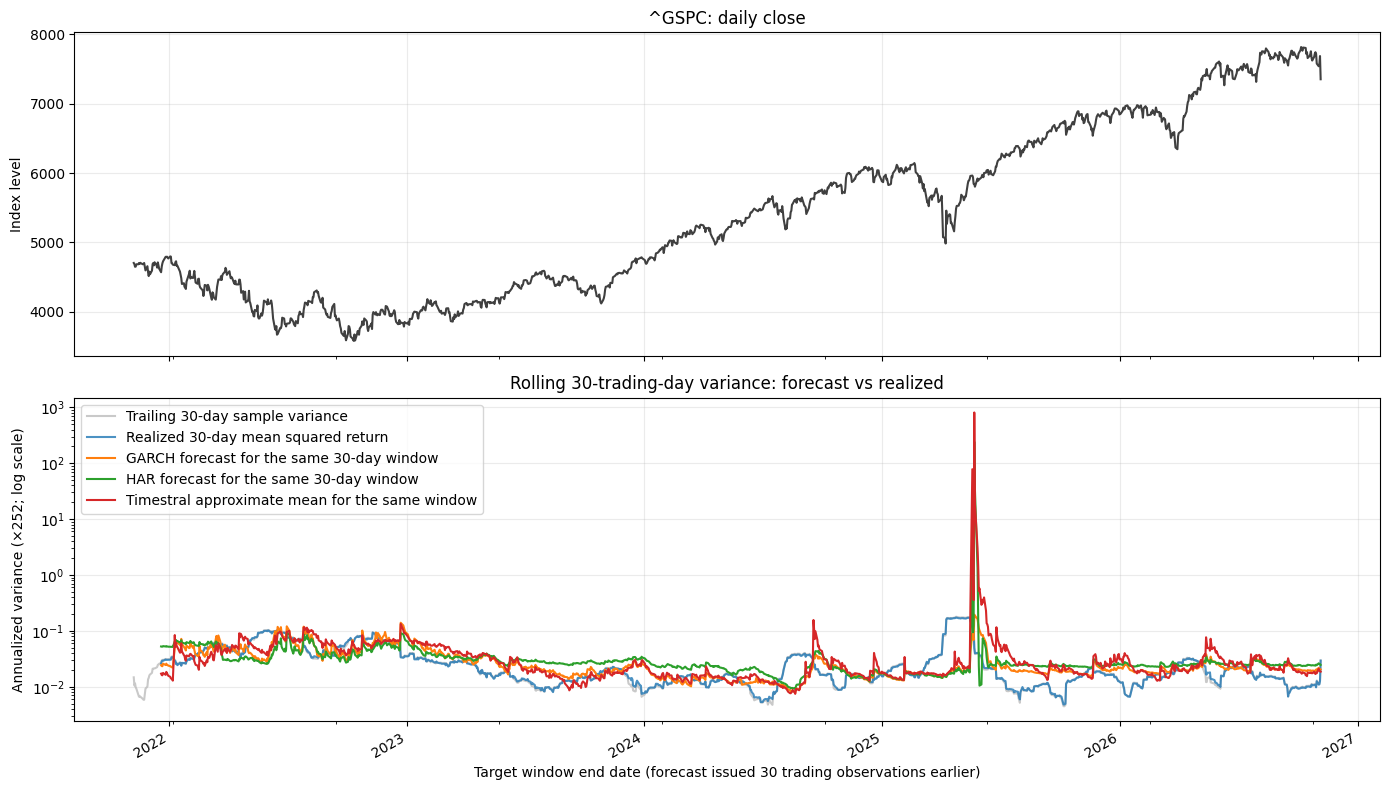

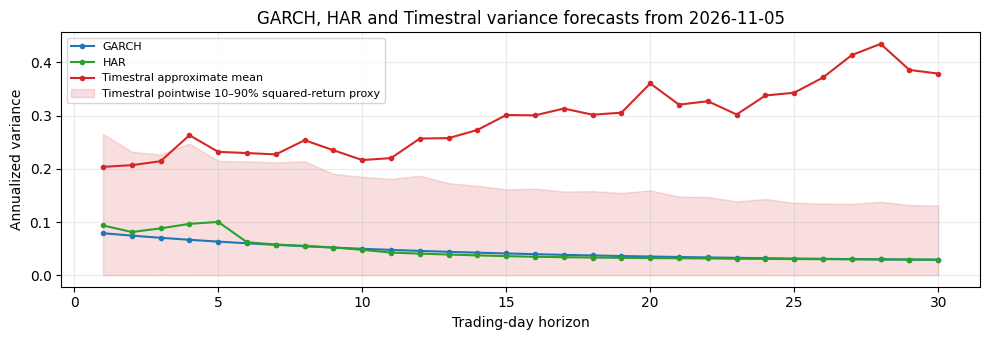

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
sp_close.loc[SP_START:].plot(ax=axes[0], color="0.25", title=f"{SP_TICKER}: daily close")
axes[0].set_ylabel("Index level")
(252*sp_trailing_var.loc[SP_START:]).plot(ax=axes[1], color="0.7", alpha=.7,
                                      label="Trailing 30-day sample variance")
(252*sp_comparison["realized_variance"]).plot(ax=axes[1], color="C0", alpha=.8,
                                            label="Realized 30-day mean squared return")
(252*sp_comparison["garch_variance"]).plot(ax=axes[1], color="C1",
                                        label="GARCH forecast for the same 30-day window")
(252*sp_comparison["har_variance"]).plot(ax=axes[1], color="C2",
                                      label="HAR forecast for the same 30-day window")
(252*sp_comparison["timestral_variance"]).plot(ax=axes[1], color="C3",
                                            label="Timestral approximate mean for the same window")
axes[1].set(title="Rolling 30-trading-day variance: forecast vs realized",
            xlabel="Target window end date (forecast issued 30 trading observations earlier)",
            ylabel="Annualized variance (decimal returns² ×252)")
axes[1].set_yscale("log")
axes[1].set_ylabel("Annualized variance (×252; log scale)")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(SP_DIR / "rolling_variance.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(np.arange(1, SP_HORIZON+1), 252*sp_latest_variance, marker=".", label="GARCH")
ax.plot(np.arange(1, SP_HORIZON+1), 252*sp_latest_har, marker=".", color="C2", label="HAR")
ax.plot(np.arange(1, SP_HORIZON+1), 252*sp_latest_timestral, color="C3", marker=".",
        label="Timestral approximate mean")
ax.fill_between(np.arange(1, SP_HORIZON+1), 252*sp_latest_ts_lo, 252*sp_latest_ts_hi,
                color="C3", alpha=.15, label="Timestral pointwise 10–90% squared-return proxy")
ax.legend(fontsize=8)
ax.set(title=f"GARCH, HAR and Timestral variance forecasts from {sp_returns.index[-1].date()}",
       xlabel="Trading-day horizon", ylabel="Annualized variance")
ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(SP_DIR / "latest_30_day_forecast.png", dpi=160)
plt.show()